# Preprocessing Data: Transaksi Retail Bian
Tahap pembersihan dan eksplorasi data transaksi ritel keranjang belanja.


### 1. Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Penjelasan:** Mengimpor library pandas, numpy, matplotlib, dan seaborn.


### 2. Load Dataset


In [2]:
import os

file_path = 'Dataset_Transaksi_Retail.csv'
url = 'https://raw.githubusercontent.com/Firdaus1802/data-preprocessing/main/01_Retail_Bian/Dataset_Transaksi_Retail.csv'

df = pd.read_csv(file_path if os.path.exists(file_path) else url)


**Penjelasan:** Dataset transaksi ritel berhasil dimuat.


### 3. Menampilkan 5 Data Teratas


In [3]:
df.head()


,Transaction_ID,Transaction_Date,Product,Category,Quantity
0,TRX1411,2025-03-30,Eggs,Breakfast,1.0
1,TRX0208,2025-06-24,Eggs,Breakfast,1.0
2,TRX0019,2025-03-26,Chips,Snacks,1.0
3,TRX1031,2025-04-19,Tissue,Personal Care,1.0
4,TRX1447,2025-02-14,Soap,Personal Care,2.0


**Penjelasan:** Menampilkan 5 baris pertama data transaksi.


### 4. Menampilkan 5 Data Terbawah


In [4]:
df.tail()


,Transaction_ID,Transaction_Date,Product,Category,Quantity
5045,TRX1327,2025-03-22,Cheese,Breakfast,2.0
5046,TRX0141,2025-05-16,Shampoo,Personal Care,1.0
5047,TRX0932,2025-04-13,Tomato Sauce,Cooking,2.0
5048,TRX1138,2025-02-07,Shampoo,Personal Care,1.0
5049,TRX0260,2025-02-20,Cheese,Breakfast,2.0


**Penjelasan:** Menampilkan 5 baris terakhir data transaksi.


### 5. Jumlah Baris


In [5]:
print('Jumlah Baris:', len(df))


Jumlah Baris: 5050


**Penjelasan:** Dataset memiliki total 5.050 baris data transaksi.


### 6. Jumlah Kolom


In [6]:
print('Jumlah Kolom:', len(df.columns))


Jumlah Kolom: 5


**Penjelasan:** Terdapat 5 kolom atribut dalam dataset.


### 7. Info Dataset


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    5050 non-null   str    
 1   Transaction_Date  5050 non-null   str    
 2   Product           5050 non-null   str    
 3   Category          5025 non-null   str    
 4   Quantity          5025 non-null   float64
dtypes: float64(1), str(4)
memory usage: 197.4 KB


**Penjelasan:** Struktur data terdiri dari 4 kolom teks dan 1 kolom numerik desimal.


### 8. Cek Missing Value


In [8]:
df.isnull().sum()


Transaction_ID       0
Transaction_Date     0
Product              0
Category            25
Quantity            25
dtype: int64

**Penjelasan:** Ditemukan masing-masing 25 missing value pada kolom Category dan Quantity.


### 9. Total Missing Value


In [9]:
print('Total Missing Value:', df.isnull().sum().sum())


Total Missing Value: 50


**Penjelasan:** Total missing value berjumlah 50 data.


### 10. Persentase Missing Value


In [10]:
persen = (df.isnull().sum().sum() / (len(df) * len(df.columns))) * 100
print(f'Persentase Missing Value: {persen:.2f}%')


Persentase Missing Value: 0.20%


**Penjelasan:** Persentase data kosong hanya 0,20% dari total seluruh sel.


### 11. Heatmap Missing Value Sebelum Imputasi


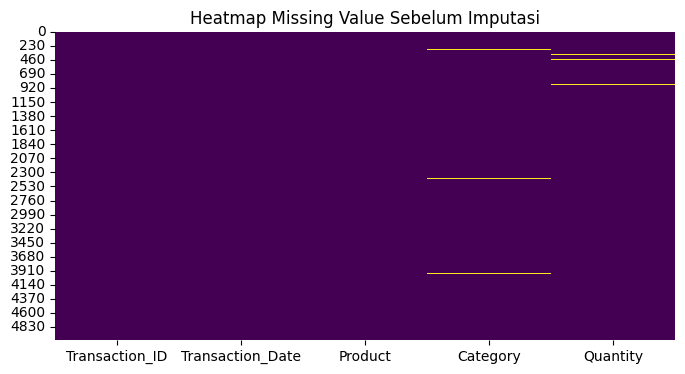

In [11]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap Missing Value Sebelum Imputasi')
plt.show()


**Penjelasan:** Garis kuning tipis menunjukkan letak 50 data kosong.


### 12. Imputasi Missing Value


In [12]:
# Imputasi Category dengan modus dan Quantity dengan median
df['Category'] = df['Category'].fillna(df['Category'].mode()[0])
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())

print('Sisa Missing Value:', df.isnull().sum().sum())


Sisa Missing Value: 0


**Penjelasan:** Nilai kosong pada Category diisi dengan modus dan Quantity dengan median. Sekarang missing value sudah 0.


### 13. Heatmap Missing Value Setelah Imputasi


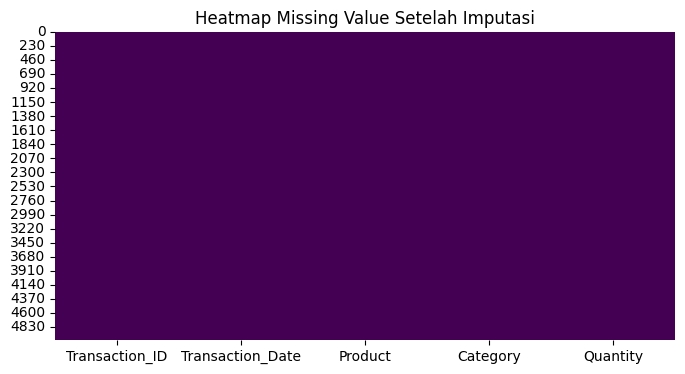

In [13]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap Missing Value Setelah Imputasi')
plt.show()


**Penjelasan:** Heatmap sekarang bersih tanpa ada data kosong.


### 14. Cek Data Duplikat


In [14]:
print('Jumlah Baris Duplikat:', df.duplicated().sum())


Jumlah Baris Duplikat: 40


**Penjelasan:** Ditemukan 40 baris data duplikat.


### 15. Hapus Data Duplikat


In [15]:
# Menghapus baris data duplikat
df = df.drop_duplicates()
print('Jumlah Duplikat Setelah Dihapus:', df.duplicated().sum())
print('Total Baris Sekarang:', len(df))


Jumlah Duplikat Setelah Dihapus: 0
Total Baris Sekarang: 5010


**Penjelasan:** Sebanyak 40 baris duplikat berhasil dihapus menggunakan fungsi drop_duplicates(), sehingga sekarang tidak ada lagi data duplikat dan tersisa 5.010 baris data.


### 16. Cek Transaksi Unik


In [16]:
print('Jumlah Transaksi Unik:', df['Transaction_ID'].nunique())


Jumlah Transaksi Unik: 1500


**Penjelasan:** Terdapat 1.500 transaksi unik (Transaction_ID).


### 17. Distribusi Kategori Produk


In [17]:
df['Category'].value_counts()


Category
Breakfast        1489
Cooking          1457
Personal Care    1060
Snacks           1004
Name: count, dtype: int64

**Penjelasan:** Produk terbagi ke dalam 4 kategori (Breakfast, Cooking, Personal Care, Snacks).


### 18. Hitung Ukuran Keranjang Belanja


In [18]:
item_per_transaksi = df.groupby('Transaction_ID')['Product'].count()


**Penjelasan:** Menghitung banyaknya item produk yang dibeli per transaksi.


### 19. Statistik Deskriptif Ukuran Keranjang


In [19]:
item_per_transaksi.describe()


count    1500.000000
mean        3.340000
std         0.849832
min         2.000000
25%         3.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Product, dtype: float64

**Penjelasan:** Rata-rata belanja adalah 3,34 barang per transaksi dengan nilai maksimum 5 barang.


### 20. Boxplot Ukuran Keranjang


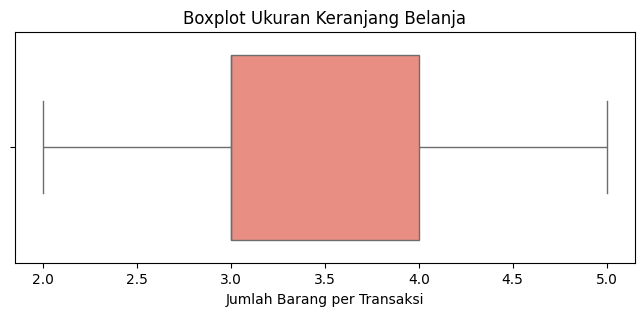

In [20]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=item_per_transaksi, color='salmon')
plt.title('Boxplot Ukuran Keranjang Belanja')
plt.xlabel('Jumlah Barang per Transaksi')
plt.show()


**Penjelasan:** Boxplot menunjukkan sebaran transaksi belanja dengan rentang 2 sampai 5 barang.


### 21. Hitung Kuartil dan IQR


In [21]:
Q1 = item_per_transaksi.quantile(0.25)
Q3 = item_per_transaksi.quantile(0.75)
IQR = Q3 - Q1

print('Q1 :', Q1)
print('Q3 :', Q3)
print('IQR:', IQR)


Q1 : 3.0
Q3 : 4.0
IQR: 1.0


**Penjelasan:** Nilai Q1 = 3, Q3 = 4, dan IQR = 1.


### 22. Hitung Batas Atas Outlier


In [22]:
batas_atas = Q3 + (1.5 * IQR)
print('Batas Atas Outlier:', batas_atas)


Batas Atas Outlier: 5.5


**Penjelasan:** Batas atas outlier adalah 5,5 barang.


### 23. Jumlah Data Outlier


In [23]:
outlier = item_per_transaksi[item_per_transaksi > batas_atas]
print('Jumlah Outlier:', len(outlier))


Jumlah Outlier: 0


**Penjelasan:** Setelah baris duplikat dihapus, nilai belanja maksimal adalah 5 barang sehingga tidak ada transaksi yang melebihi batas atas 5,5 (0 outlier).


### 24. Daftar Transaksi Outlier


In [24]:
outlier.sort_values(ascending=False).head()


Series([], Name: Product, dtype: int64)

**Penjelasan:** Tidak ada transaksi outlier setelah baris duplikat dibersihkan.
